In [1]:
import numpy as np
import matplotlib.pyplot as plt

from correlation import compute_correlation_C
from drives import DRIVE_REGIMES
from solver import compute_decoherence

plt.rcParams['figure.dpi'] = 120
plt.rcParams['font.size'] = 10

In [2]:
t_max = 25.0
n_t = 3000
t_grid = np.linspace(0.0, t_max, n_t + 1)

print("Calculating vacuum correlation function C(s)...")
C_values = compute_correlation_C(t_grid, m=1.0, sigma_x=1.0)
C_real = C_values.real
print("Done! C(0) =", C_real[0])

Calculating vacuum correlation function C(s)...
Done! C(0) = 0.24256954255867022


In [3]:
simulation_results = {}

for name, drive_func in DRIVE_REGIMES.items():
    print(f"Running simulation for regime: [{name}]...")
    eps_vals, d_eps_vals = drive_func(t_grid)
    
    res = compute_decoherence(t_grid, C_real, eps_vals, d_eps_vals)
    res["eps"] = eps_vals
    res["d_eps"] = d_eps_vals
    
    simulation_results[name] = res

print("\nAll regimes simulated successfully!")

Running simulation for regime: [gaussian]...
Running simulation for regime: [periodic_smooth]...
Running simulation for regime: [periodic_square]...
Running simulation for regime: [step]...
Running simulation for regime: [delta]...

All regimes simulated successfully!


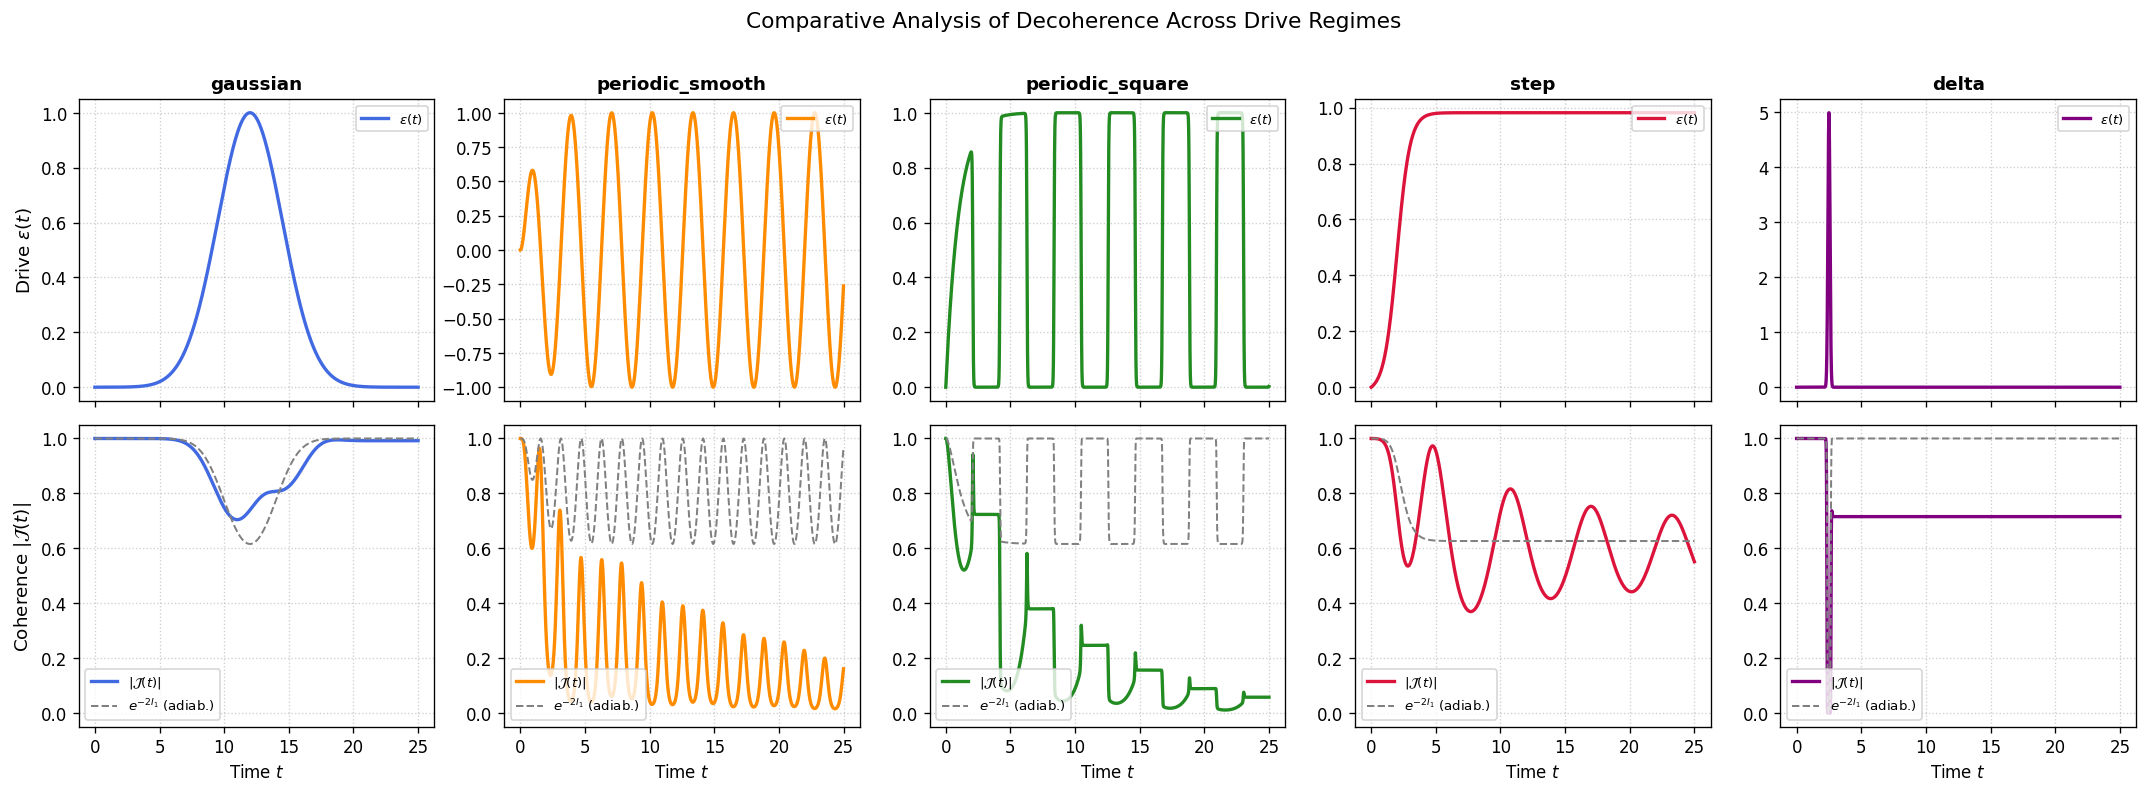

In [4]:
regime_names = list(simulation_results.keys())
n_regimes = len(regime_names)

fig, axes = plt.subplots(2, n_regimes, figsize=(3.6 * n_regimes, 6.5), sharex=True)

colors = {
    "gaussian": "royalblue",
    "periodic_smooth": "darkorange",
    "periodic_square": "forestgreen",
    "step": "crimson",
    "delta": "purple"
}

for col_idx, name in enumerate(regime_names):
    data = simulation_results[name]
    c = colors.get(name, "black")
    
    ax_top = axes[0, col_idx]
    ax_top.plot(t_grid, data["eps"], color=c, lw=2.0, label=r"$\epsilon(t)$")
    ax_top.set_title(f"{name}", fontsize=11, fontweight="bold")
    ax_top.grid(True, ls=":", alpha=0.6)
    if col_idx == 0:
        ax_top.set_ylabel(r"Drive $\epsilon(t)$", fontsize=11)
    ax_top.legend(loc="upper right", frameon=True, fontsize=8)

    ax_bot = axes[1, col_idx]
    ax_bot.plot(t_grid, data["J_abs"], color=c, lw=2.0, label=r"$|\mathcal{J}(t)|$")
    ax_bot.plot(t_grid, np.exp(-2.0 * data["I_1"]), color="gray", ls="--", lw=1.2, label=r"$e^{-2I_1}$ (adiab.)")
    ax_bot.set_xlabel("Time $t$", fontsize=10)
    ax_bot.set_ylim(-0.05, 1.05)
    ax_bot.grid(True, ls=":", alpha=0.6)
    if col_idx == 0:
        ax_bot.set_ylabel(r"Coherence $|\mathcal{J}(t)|$", fontsize=11)
    ax_bot.legend(loc="lower left", frameon=True, fontsize=8)

plt.suptitle("Comparative Analysis of Decoherence Across Drive Regimes", fontsize=13, y=1.01)
plt.tight_layout()
plt.show()

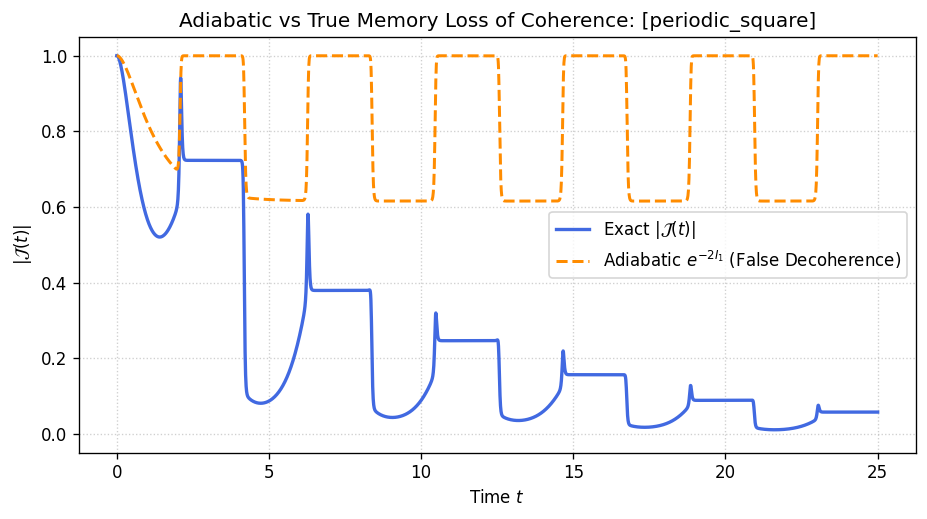

In [5]:
regime_to_inspect = "periodic_square"
data = simulation_results[regime_to_inspect]

plt.figure(figsize=(9, 4.5))
plt.plot(t_grid, data["J_abs"], label=r"Exact $|\mathcal{J}(t)|$", color="royalblue", lw=2)
plt.plot(t_grid, np.exp(-2.0 * data["I_1"]), label=r"Adiabatic $e^{-2 I_1}$ (False Decoherence)", color="darkorange", ls="--", lw=1.8)

plt.title(f"Adiabatic vs True Memory Loss of Coherence: [{regime_to_inspect}]")
plt.xlabel("Time $t$")
plt.ylabel(r"$|\mathcal{J}(t)|$")
plt.ylim(-0.05, 1.05)
plt.grid(True, ls=":", alpha=0.6)
plt.legend()
plt.show()